# EDA

Goal: predict `posted_rate` for Nov-Dec 2025 loads, using labeled loads from Jan-Oct 2025.

## Columns

No data dictionary was provided, so the meanings are my best guess.

| Column | Meaning |
|---|---|
| `load_id` | Row ID |
| `pickup`, `delivery` | Start and end city |
| `pickup_lat`, `pickup_lon`, `delivery_lat`, `delivery_lon` | City coordinates |
| `distance` | Trip length in miles |
| `equipment` | Trailer type: Dry Van, Reefer (refrigerated), or Flatbed |
| `weight` | Cargo weight in pounds |
| `date` | Day of the load |
| `market_index` | Seems to track how expensive the market is that day |
| `quote_signal` | Unknown |
| `posted_rate` | Target: total price of the load in dollars |

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.width", 200, "display.max_columns", 20)
train = pd.read_csv("../data/train_test.csv", parse_dates=["date"])
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])
template = pd.read_csv("../data/validation_predictions_template.csv")
december = pd.read_csv("../data/december_chart_inputs.csv")

In [2]:
row = train.iloc[0]
print(row.to_string())
print("rate per mile:", round(row.posted_rate / row.distance, 2))

load_id                   TR-000001
pickup                     Richmond
delivery                  Baltimore
pickup_lat                 38.09122
pickup_lon                -76.78906
delivery_lat               38.16908
delivery_lon              -72.74564
distance                      274.3
equipment                   Dry Van
weight                      30658.0
date            2025-01-01 00:00:00
market_index                0.95684
quote_signal                2.39595
posted_rate                  645.41
rate per mile: 2.35


In [3]:
for name, df in {"train_test": train, "validation": val, "template": template, "december": december}.items():
    print(name, df.shape, list(df.columns))

print(december[["pickup", "delivery", "distance", "equipment", "weight"]].drop_duplicates())
print("December dates:", december.date.nunique())

train_test (48000, 14) ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
validation (12000, 13) ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
template (12000, 2) ['load_id', 'predicted_rate']
december (31, 7) ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
      pickup    delivery  distance equipment  weight
0  Lexington  Fort Wayne       360   Dry Van   32000
December dates: 31


In [4]:
print(train.select_dtypes("number").describe().T[["min", "50%", "max"]].round(2))
print("share missing:")
print(train.isna().mean().round(4)[lambda s: s > 0])
print(train.equipment.value_counts(normalize=True).round(3))

                   min       50%       max
pickup_lat       28.36     35.29     44.30
pickup_lon     -121.70    -88.09    -69.50
delivery_lat     28.36     35.29     44.30
delivery_lon   -121.70    -87.53    -69.50
distance         70.00    953.30   3439.80
weight       -47500.00  31436.50  47500.00
market_index      0.68      1.06      1.47
quote_signal      0.69      2.06      3.61
posted_rate      57.22   2030.76  25533.00
share missing:
weight          0.0062
market_index    0.0078
dtype: float64
equipment
Dry Van    0.567
Reefer     0.251
Flatbed    0.182
Name: proportion, dtype: float64


In [5]:
print("cities in train:", len(set(train.pickup) | set(train.delivery)),
      "| in validation:", len(set(val.pickup) | set(val.delivery)))
print("distances on one lane, at most:", train.groupby(["pickup", "delivery"]).distance.nunique().max())

size = train.weight.abs()
print("weight ignoring the sign:", size.min(), "to", size.max(), "median", size.median())
print("negative share:", round((train.weight < 0).mean(), 4), "| at 47,500:", (size == 47500).sum())

print("loads per day, median:", train.groupby("date").size().median())
print("market spread within a day, median:", round(train.groupby("date").market_index.std().median(), 3))

cities in train: 64 | in validation: 72
distances on one lane, at most: 38
weight ignoring the sign: 5000.0 to 47500.0 median 31496.0
negative share: 0.0061 | at 47,500: 1204
loads per day, median: 157.0
market spread within a day, median: 0.025


## Columns I add

- `rate_per_mile`: `posted_rate / distance`
- `rate_ratio`: a load's rate per mile divided by the median for similar loads. 1.0 is typical.
- `log_ratio`: log of `rate_ratio`

In [6]:
# For analysis in the EDA
train["rate_per_mile"] = train.posted_rate / train.distance
train["month"] = train.date.dt.to_period("M")
band = pd.qcut(train.distance, 12, duplicates="drop")
typical = train.groupby(["equipment", band], observed=True).rate_per_mile.transform("median")
train["rate_ratio"] = train.rate_per_mile / typical
train["log_ratio"] = np.log(train.rate_ratio)
print(train[["posted_rate", "distance", "rate_per_mile", "month", "rate_ratio", "log_ratio"]].head().round(3))

   posted_rate  distance  rate_per_mile    month  rate_ratio  log_ratio
0       645.41     274.3          2.353  2025-01       0.917     -0.087
1       679.97     280.5          2.424  2025-01       0.838     -0.177
2      1802.54     967.8          1.863  2025-01       0.918     -0.086
3      1827.28     965.4          1.893  2025-01       0.933     -0.070
4      1380.28     541.9          2.547  2025-01       1.008      0.008


Features used by the model:

In [7]:
# For the model
a, b, c, d = map(np.radians, (train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon))
train["haversine"] = 3958.8 * 2 * np.arcsin(np.sqrt(np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2))
train["log_distance"] = np.log(train.distance)
train["weight_clean"] = train.weight.abs().fillna(train.weight.abs().median())
market_daily = pd.concat([train, val]).groupby("date").market_index.mean()
train["market_daily"] = train.date.map(market_daily)
train["market"] = train.market_index.fillna(train.market_daily)
train["months_elapsed"] = (train.date - pd.Timestamp("2025-01-01")).dt.days / 30
train["day_of_week"] = train.date.dt.dayofweek
print(train[["distance", "log_distance", "haversine", "weight", "weight_clean", "market_index",
             "market_daily", "market", "months_elapsed", "day_of_week"]].head().round(3))

   distance  log_distance  haversine   weight  weight_clean  market_index  market_daily  market  months_elapsed  day_of_week
0     274.3         5.614    219.809  30658.0       30658.0         0.957         0.961   0.957             0.0            2
1     280.5         5.637    220.526  17555.0       17555.0         0.976         0.961   0.976             0.0            2
2     967.8         6.875    826.920  31721.0       31721.0         1.010         0.961   1.010             0.0            2
3     965.4         6.873    840.541  32333.0       32333.0         0.945         0.961   0.945             0.0            2
4     541.9         6.295    434.163  35183.0       35183.0         0.985         0.961   0.985             0.0            2


Premium columns: `reefer_dollars` is the median Reefer rate minus the median Dry Van rate in a distance band. `reefer_pct` is the same gap as a percentage.

In [8]:
bands = pd.cut(train.distance, [0, 250, 500, 1000, 1500, 2000, 4000])
rates = train.groupby([bands, "equipment"], observed=True).posted_rate.median().unstack()
print(rates.round(0))
print(pd.DataFrame({
    "reefer_dollars": (rates["Reefer"] - rates["Dry Van"]).round(0),
    "reefer_pct": ((rates["Reefer"] / rates["Dry Van"] - 1) * 100).round(1),
    "flatbed_pct": ((rates["Flatbed"] / rates["Dry Van"] - 1) * 100).round(1),
}))

equipment     Dry Van  Flatbed  Reefer
distance                              
(0, 250]        483.0    534.0   551.0
(250, 500]      885.0    956.0   999.0
(500, 1000]    1561.0   1692.0  1771.0
(1000, 1500]   2406.0   2596.0  2705.0
(1500, 2000]   3366.0   3667.0  3812.0
(2000, 4000]   4308.0   4651.0  4875.0
              reefer_dollars  reefer_pct  flatbed_pct
distance                                             
(0, 250]                68.0        14.1         10.4
(250, 500]             113.0        12.8          8.0
(500, 1000]            211.0        13.5          8.4
(1000, 1500]           299.0        12.4          7.9
(1500, 2000]           447.0        13.3          8.9
(2000, 4000]           566.0        13.1          8.0


## Shape of the problem

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train_test.csv", parse_dates=["date"])
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])
december = pd.read_csv("../data/december_chart_inputs.csv")

train["rate_per_mile"] = train.posted_rate / train.distance
train["month"] = train.date.dt.to_period("M")
val["month"] = val.date.dt.to_period("M")

print(train.date.min().date(), train.date.max().date(), len(train))
print(val.date.min().date(), val.date.max().date(), len(val))
print("not in December file:", sorted(set(val.columns) - set(december.columns) - {"month"}))
print("duplicates:", train.load_id.duplicated().sum(), train.drop(columns="load_id").duplicated().sum())
print("non-positive rates:", (train.posted_rate <= 0).sum())

2025-01-01 2025-10-31 48000
2025-11-01 2025-12-31 12000
not in December file: ['delivery_lat', 'delivery_lon', 'load_id', 'market_index', 'pickup_lat', 'pickup_lon', 'quote_signal']
duplicates: 0 0
non-positive rates: 0


Validation comes entirely after training, so this is forecasting. There are no duplicates. The December file has no coordinates, `market_index`, or `quote_signal`.

## Does it behave like freight?

In [10]:
distance_bands = pd.cut(train.distance, [0, 250, 500, 1000, 1500, 2000, 4000])
print(train.groupby(distance_bands, observed=True).rate_per_mile.median().round(2))
print(train.groupby("equipment").rate_per_mile.median().round(2))

distance
(0, 250]        2.75
(250, 500]      2.42
(500, 1000]     2.20
(1000, 1500]    2.08
(1500, 2000]    2.00
(2000, 4000]    1.91
Name: rate_per_mile, dtype: float64
equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31
Name: rate_per_mile, dtype: float64


Short hauls cost more per mile, and Reefers cost the most.

## Do effects add or multiply?

In [11]:
bands = pd.cut(train.distance, [0, 250, 500, 1000, 1500, 2000, 4000])
rates = train.groupby([bands, "equipment"], observed=True).posted_rate.median().unstack()
print(pd.DataFrame({
    "reefer_dollars": (rates["Reefer"] - rates["Dry Van"]).round(0),
    "reefer_pct": ((rates["Reefer"] / rates["Dry Van"] - 1) * 100).round(1),
    "flatbed_pct": ((rates["Flatbed"] / rates["Dry Van"] - 1) * 100).round(1),
}))

long_haul = train.distance > 1000
monthly = train.groupby(["month", long_haul]).agg(
    rate=("posted_rate", "median"), per_mile=("rate_per_mile", "median")).unstack()
print(pd.DataFrame({
    "short_pct": ((monthly["per_mile"][False] / monthly["per_mile"][False].iloc[0] - 1) * 100).round(1),
    "long_pct": ((monthly["per_mile"][True] / monthly["per_mile"][True].iloc[0] - 1) * 100).round(1),
    "short_dollars": (monthly["rate"][False] - monthly["rate"][False].iloc[0]).round(0),
    "long_dollars": (monthly["rate"][True] - monthly["rate"][True].iloc[0]).round(0),
}))

              reefer_dollars  reefer_pct  flatbed_pct
distance                                             
(0, 250]                68.0        14.1         10.4
(250, 500]             113.0        12.8          8.0
(500, 1000]            211.0        13.5          8.4
(1000, 1500]           299.0        12.4          7.9
(1500, 2000]           447.0        13.3          8.9
(2000, 4000]           566.0        13.1          8.0
         short_pct  long_pct  short_dollars  long_dollars
month                                                    
2025-01        0.0       0.0            0.0           0.0
2025-02        0.9       1.5           69.0          20.0
2025-03        5.5       5.1           74.0         188.0
2025-04        5.8       5.9          103.0         185.0
2025-05        7.8       8.3          127.0         262.0
2025-06       10.9      10.5          163.0         376.0
2025-07        7.7       8.0          121.0         272.0
2025-08        4.5       4.5           70.0   

The Reefer premium grows from $68 to $566 in dollars but stays around 13%, so it isn't a flat fee. Market moves look similar: close in percent, far apart in dollars. This points to percentage effects, so I'll try modeling log(rate).

## Corrupted rates

In [12]:
band = pd.qcut(train.distance, 12, duplicates="drop")
typical = train.groupby(["equipment", band], observed=True).rate_per_mile.transform("median")
train["rate_ratio"] = train.rate_per_mile / typical

print(pd.cut(train.rate_ratio, [0, .5, .6, .8, 1.2, 1.3, 1.5, 2, 6.5]).value_counts().sort_index())
clean = train[train.rate_ratio.between(0.6, 1.6)].copy()
clean["log_ratio"] = np.log(clean.rate_ratio)
print(len(train) - len(clean), round(1 - len(clean) / len(train), 4))

rate_ratio
(0.0, 0.5]      337
(0.5, 0.6]        0
(0.6, 0.8]        0
(0.8, 1.2]    47303
(1.2, 1.3]       20
(1.3, 1.5]        0
(1.5, 2.0]        0
(2.0, 6.5]      340
Name: count, dtype: int64
677 0.0141


677 rows (1.41%) are about 2-6x away from similar loads, with a clear gap from normal rows. I drop them from training only, since they can't be identified in validation without the rate.

## Weights and missing values

In [13]:
for name, df in [("train", train), ("val", val)]:
    print(name, "negative", round((df.weight < 0).mean(), 4),
          "null", round(df.weight.isna().mean(), 4),
          "market null", round(df.market_index.isna().mean(), 4))
print(train.weight.abs().value_counts().head(2))

negative, positive = clean[clean.weight < 0], clean[clean.weight > 0]
print("negative rows:", round(negative.log_ratio.corr(negative.weight.abs()), 3),
      "positive rows:", round(positive.log_ratio.corr(positive.weight), 3))
weight_bands = pd.cut(clean.weight.abs(), [0, 15000, 25000, 30000, 35000, 40000, 47500])
print(clean.groupby(weight_bands, observed=True).log_ratio.mean().round(3))

train negative 0.0061 null 0.0062 market null 0.0078
val negative 0.0121 null 0.0138 market null 0.0208
weight
47500.0    1204
5000.0       32
Name: count, dtype: int64
negative rows: 0.406 positive rows: 0.458
weight
(0, 15000]       -0.047
(15000, 25000]   -0.035
(25000, 30000]   -0.016
(30000, 35000]    0.006
(35000, 40000]    0.023
(40000, 47500]    0.031
Name: log_ratio, dtype: float64


Negative weights look like sign errors: after `abs()` they relate to price about like normal weights. Missing values are about twice as common in validation. Plan: `abs()`, fill with the training median, keep the caps at 5,000 and 47,500.

## Geography

In [14]:
a, b, c, d = map(np.radians, (train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon))
haversine = 3958.8 * 2 * np.arcsin(np.sqrt(np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2))
print((train.distance / haversine).describe().round(3)[["min", "50%", "max"]])
print(train.groupby("pickup")[["pickup_lat", "pickup_lon"]].first().loc[["Los Angeles", "Boston"]].round(2))
print("rows at the 70-mile floor:", (train.distance == 70).sum())

min    1.058
50%    1.182
max    9.635
dtype: float64
             pickup_lat  pickup_lon
pickup                             
Los Angeles       28.57      -116.7
Boston            39.27       -69.5
rows at the 70-mile floor: 48


The coordinates don't match a real map, but each city's values are consistent. Road distance is typically about 1.18x straight-line distance. I leave these as they are.

## Unseen cities

In [15]:
seen = set(train.pickup) | set(train.delivery)
unseen = (set(val.pickup) | set(val.delivery)) - seen
print(sorted(unseen))
print(round((val.pickup.isin(unseen) | val.delivery.isin(unseen)).mean(), 3))
print("Laredo latitude:", val.loc[val.pickup == "Laredo", "pickup_lat"].iloc[0],
      "| training minimum:", train.pickup_lat.min())

['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
0.121
Laredo latitude: 25.5 | training minimum: 28.35765


12.1% of validation rows touch a city that isn't in training, and Laredo is outside the training latitude range. So I use coordinates, not city names.

## `quote_signal`

In [16]:
print(clean.groupby("month").apply(
    lambda m: round(m.quote_signal.corr(m.rate_per_mile), 3), include_groups=False))
print(clean.groupby(["month", "equipment"]).quote_signal.mean().unstack().round(2))
print(val.groupby(["month", "equipment"]).quote_signal.mean().unstack().round(2))

month
2025-01    0.996
2025-02    0.996
2025-03    0.997
2025-04   -0.993
2025-05   -0.994
2025-06    0.997
2025-07   -0.994
2025-08   -0.020
2025-09    0.997
2025-10   -0.994
Freq: M, dtype: float64
equipment  Dry Van  Flatbed  Reefer
month                              
2025-01       1.98     2.13    2.23
2025-02       2.00     2.16    2.26
2025-03       2.07     2.28    2.35
2025-04       2.06     1.92    1.79
2025-05       2.01     1.85    1.74
2025-06       2.17     2.42    2.49
2025-07       2.02     1.84    1.75
2025-08       2.06     2.04    2.05
2025-09       2.08     2.31    2.38
2025-10       2.03     1.88    1.79
equipment  Dry Van  Flatbed  Reefer
month                              
2025-11       2.05     2.06    2.06
2025-12       2.05     2.04    2.05


It looks almost perfect, but its correlation with rate per mile flips: about +0.99 in some months, -0.99 in others, and about 0 in August. Nov-Dec look like August by equipment. I'm dropping it.

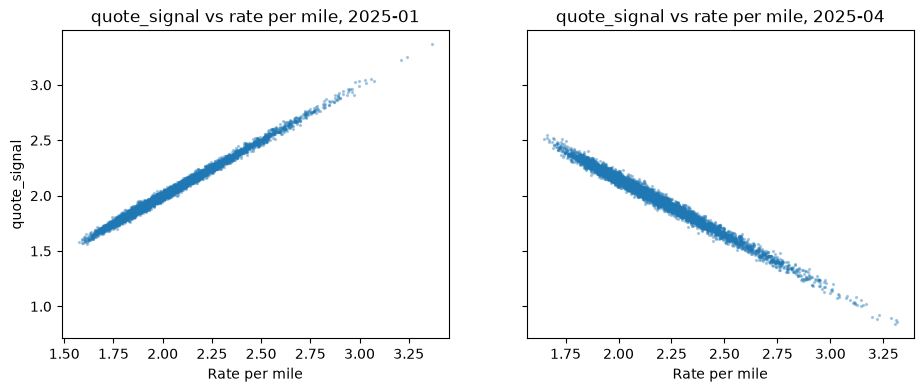

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, month in zip(axes, ["2025-01", "2025-04"]):
    rows = clean[clean.month == month]
    axis.scatter(rows.rate_per_mile, rows.quote_signal, s=2, alpha=0.3)
    axis.set(title=f"quote_signal vs rate per mile, {month}", xlabel="Rate per mile")
axes[0].set_ylabel("quote_signal")
plt.show()

## `market_index`

In [18]:
level = clean.groupby("month").agg(log_ratio=("log_ratio", "mean"), market=("market_index", "mean"))
print(level.round(3))
print(val.groupby("month").market_index.mean().round(3))
print(clean.groupby(clean.date.dt.dayofweek).agg(
    log_ratio=("log_ratio", "mean"), market=("market_index", "mean")).round(3))

         log_ratio  market
month                     
2025-01     -0.055   0.927
2025-02     -0.040   0.996
2025-03     -0.004   1.073
2025-04      0.000   1.207
2025-05      0.023   1.301
2025-06      0.047   1.280
2025-07      0.018   1.201
2025-08     -0.012   0.981
2025-09      0.005   0.893
2025-10      0.008   0.957
month
2025-11    0.919
2025-12    0.935
Freq: M, Name: market_index, dtype: float64
      log_ratio  market
date                   
0        -0.009   1.000
1        -0.002   1.075
2         0.007   1.153
3         0.010   1.179
4         0.005   1.134
5        -0.005   1.048
6        -0.011   0.989


January and September have similar market values (0.927 and 0.893), but September rates are about 6% higher. So there's a market effect and a slow drift. The model needs both.

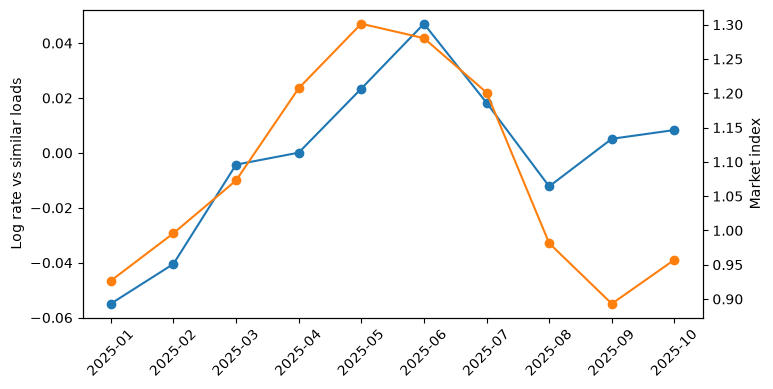

In [19]:
fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(level.index.astype(str), level.log_ratio, marker="o", label="Rate level")
axis.set_ylabel("Log rate vs similar loads")
other = axis.twinx()
other.plot(level.index.astype(str), level.market, marker="o", color="tab:orange", label="Market index")
other.set_ylabel("Market index")
axis.tick_params(axis="x", rotation=45)
plt.show()

## December file

In [20]:
daily_market = pd.concat([train, val]).groupby("date").market_index.mean()
dates = pd.to_datetime(december.date)
print("December dates with a market value:", daily_market.reindex(dates).notna().sum(), "of", len(dates))
print("fewest loads behind a December value:", val[val.date.isin(dates)].groupby("date").market_index.count().min())
print("spread of market within a day:", round(val.groupby("date").market_index.std().mean(), 3))
print(daily_market.reindex(dates).round(3).head(7).to_string())

print("Lexington in pickups:", (train.pickup == "Lexington").any(),
      "| Fort Wayne in deliveries:", (train.delivery == "Fort Wayne").any())
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne")]
print("December lane rows:", len(lane), "Dry Van:", (lane.equipment == "Dry Van").sum())

December dates with a market value: 31 of 31
fewest loads behind a December value: 159
spread of market within a day: 0.025
date
2025-12-01    0.835
2025-12-02    0.915
2025-12-03    0.994
2025-12-04    1.024
2025-12-05    0.975
2025-12-06    0.889
2025-12-07    0.831
Lexington in pickups: True | Fort Wayne in deliveries: True
December lane rows: 32 Dry Van: 21


Both gaps can be filled: market from the daily average in `validation.csv`, coordinates from training rows.

## Decisions

- Validate by time
- Model log(rate), with a curve for distance
- Drop corrupted rates from training
- Weight: `abs()`, median fill, keep caps
- Use coordinates, not city names
- Drop `quote_signal`
- Use separate market and time terms